In [1]:
import pandas as pd
df=pd.read_csv("heart.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [2]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [3]:
df.fillna(df.mean(numeric_only=True), inplace=True)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


In [4]:
#Fill with Mode for categorical data

In [5]:
for col in df.select_dtypes(include=['object', 'string']).columns:
    df[col].fillna(df[col].mode()[0], inplace=True)

In [6]:
#Convert Categorical Data - Numbers (encoding)

In [7]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for col in df.select_dtypes(include=['object', 'string']).columns:
    df[col] = le.fit_transform(df[col])

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, roc_curve

In [9]:
 #feature scaling i mean normalization of dataset

In [10]:
scaler = StandardScaler()

df_scaled = scaler.fit_transform(df)

In [11]:
#df_scaled = scaler.fit_transform(df) and by using this sentence our data becomes an array

In [12]:
df_scaled = scaler.fit_transform(df)

In [13]:
#now we need to convert it into dataframe

In [14]:
df_scaled = pd.DataFrame(df_scaled, columns=df.columns)

In [15]:
#check clean data

In [16]:
df_scaled.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,0.952197,0.681005,1.973123,0.763956,-0.256334,2.394438,-1.005832,0.015443,-0.696631,1.087338,-2.274579,-0.714429,-2.148873,0.914529
1,-1.915313,0.681005,1.002577,-0.092738,0.072199,-0.417635,0.898962,1.633471,-0.696631,2.122573,-2.274579,-0.714429,-0.512922,0.914529
2,-1.474158,-1.468418,0.032031,-0.092738,-0.816773,-0.417635,-1.005832,0.977514,-0.696631,0.310912,0.976352,-0.714429,-0.512922,0.914529
3,0.180175,0.681005,0.032031,-0.663867,-0.198357,-0.417635,0.898962,1.239897,-0.696631,-0.206705,0.976352,-0.714429,-0.512922,0.914529
4,0.290464,-1.468418,-0.938515,-0.663867,2.082050,-0.417635,0.898962,0.583939,1.435481,-0.379244,0.976352,-0.714429,-0.512922,0.914529


In [17]:
target = "target"  #change it if your column name is different

In [18]:
X = df.drop("target", axis=1)
y = df["target"]

In [19]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='str')

In [20]:
#now we will split data into:
#Training set - model learns from this
#Testing set - we evaluate model performance
#this ensures that the model works on unseen data

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [22]:
test_size=0.2#(20% - testing,80% - training)

In [23]:
random_state=42#(Fixes randomness)

In [24]:
#now after splitting check the data

In [25]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(242, 13)
(61, 13)
(242,)
(61,)


In [26]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

C:\Users\Dell\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [27]:
from sklearn.tree import DecisionTreeClassifier

# create model
model = DecisionTreeClassifier(random_state=42)

# train model
model.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

In [28]:
y_pred = model.predict(X_test)

In [29]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.7540983606557377


In [30]:
from sklearn.metrics import classification_report, confusion_matrix

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Confusion Matrix:
 [[25  4]
 [11 21]]

Classification Report:
               precision    recall  f1-score   support

           0       0.69      0.86      0.77        29
           1       0.84      0.66      0.74        32

    accuracy                           0.75        61
   macro avg       0.77      0.76      0.75        61
weighted avg       0.77      0.75      0.75        61



In [31]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

from sklearn.metrics import accuracy_score
rf_acc = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_acc)

Random Forest Accuracy: 0.8360655737704918


In [32]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

xgb_model = XGBClassifier(eval_metric='logloss', random_state=42)

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)

xgb_acc = accuracy_score(y_test, xgb_pred)

print("XGBoost Accuracy:", xgb_acc)

XGBoost Accuracy: 0.819672131147541


In [33]:
print("Logistic Regression:", accuracy)
print("Random Forest:", rf_acc)
print("XGBoost:", xgb_acc)

Logistic Regression: 0.7540983606557377
Random Forest: 0.8360655737704918
XGBoost: 0.819672131147541


In [34]:
from sklearn.metrics import classification_report, confusion_matrix

print(confusion_matrix(y_test, rf_pred))
print(classification_report(y_test, rf_pred))

[[24  5]
 [ 5 27]]
              precision    recall  f1-score   support

           0       0.83      0.83      0.83        29
           1       0.84      0.84      0.84        32

    accuracy                           0.84        61
   macro avg       0.84      0.84      0.84        61
weighted avg       0.84      0.84      0.84        61



In [35]:
import pandas as pd

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(by='Importance', ascending=False)

print(feature_importance)

     Feature  Importance
9    oldpeak    0.128485
7    thalach    0.119725
11        ca    0.115533
2         cp    0.103792
12      thal    0.093300
0        age    0.092811
3   trestbps    0.077537
8      exang    0.075809
4       chol    0.074812
10     slope    0.051058
1        sex    0.035658
6    restecg    0.019782
5        fbs    0.011698


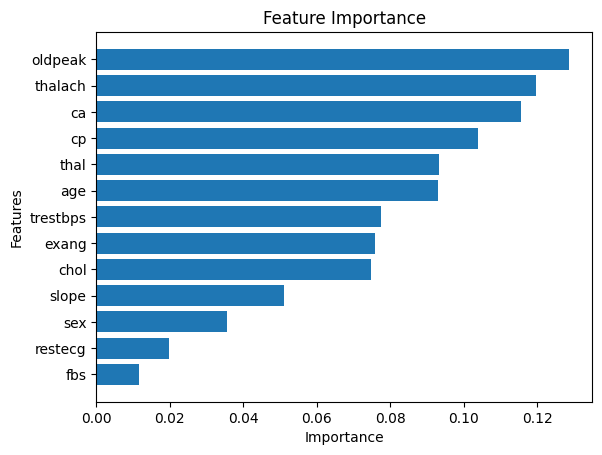

In [36]:
import matplotlib.pyplot as plt

plt.figure()
plt.barh(feature_importance['Feature'], feature_importance['Importance'])
plt.gca().invert_yaxis()
plt.title("Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()

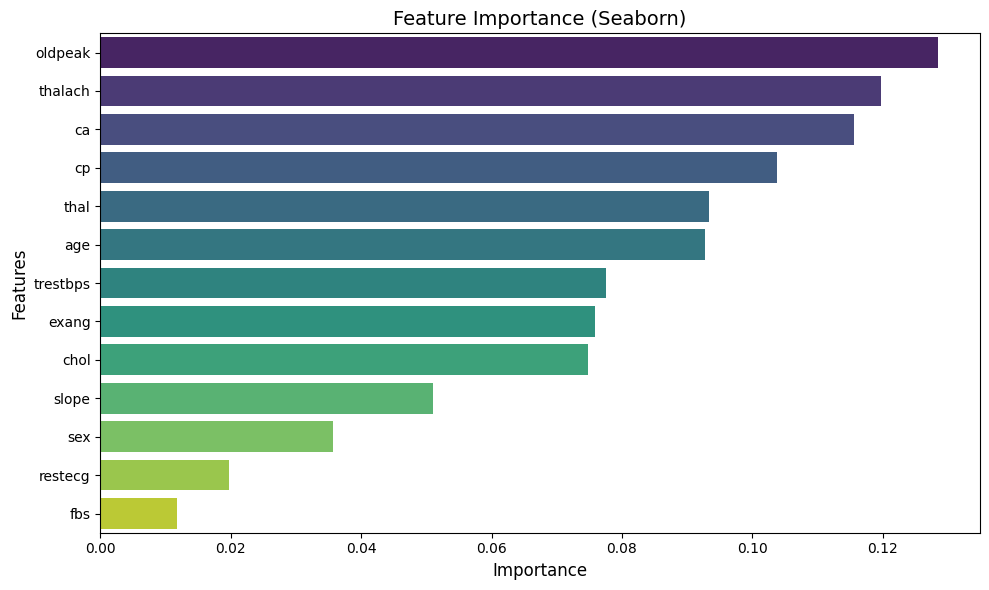

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

sns.barplot(
    x='Importance',
    y='Feature',
    hue='Feature',          # 👈 add this
    data=feature_importance,
    palette='viridis',
    legend=False            # 👈 add this
)

plt.title("Feature Importance (Seaborn)", fontsize=14)
plt.xlabel("Importance", fontsize=12)
plt.ylabel("Features", fontsize=12)

plt.tight_layout()
plt.show()

C:\Users\Dell\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


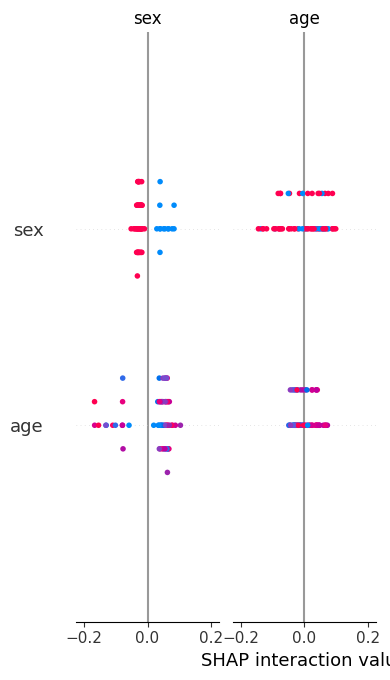

In [38]:
import shap

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, plot_type="bar")

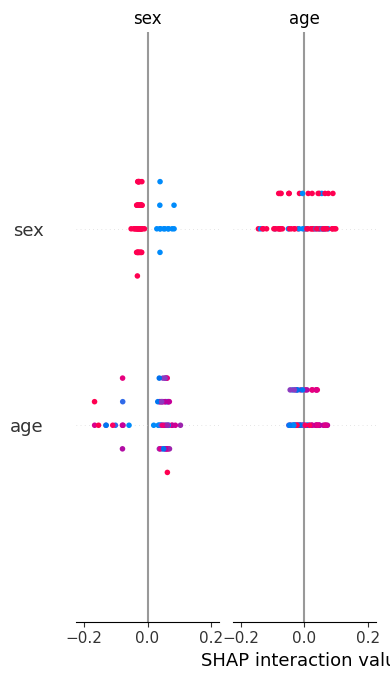

In [39]:
#shap.plots.bar(shap_values)
import shap

shap.summary_plot(shap_values, X_test, plot_type="bar")


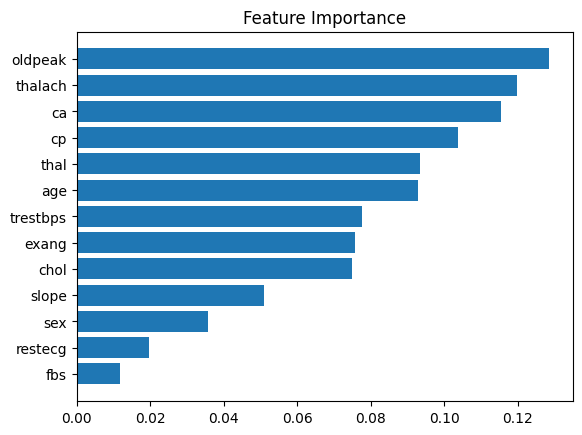

In [40]:
import matplotlib.pyplot as plt

plt.barh(feature_importance['Feature'], feature_importance['Importance'])
plt.gca().invert_yaxis()
plt.title("Feature Importance")
plt.show()

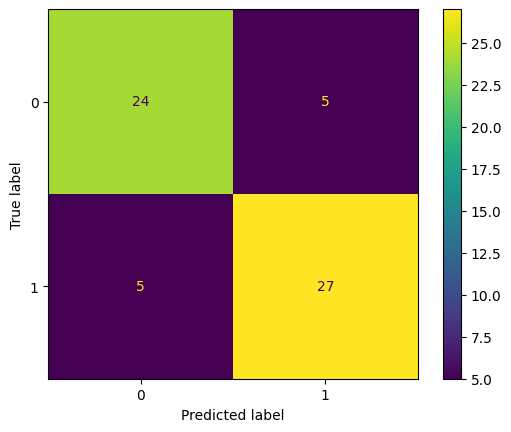

In [41]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(rf_model, X_test, y_test)

In [42]:
print(X_test.columns)

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal'],
      dtype='str')


In [43]:
import numpy as np

print("X_test shape:", X_test.shape)

if hasattr(shap_values, "values"):
    print("SHAP values shape:", shap_values.values.shape)
else:
    print("SHAP values shape:", np.array(shap_values).shape)

X_test shape: (61, 13)
SHAP values shape: (61, 13, 2)


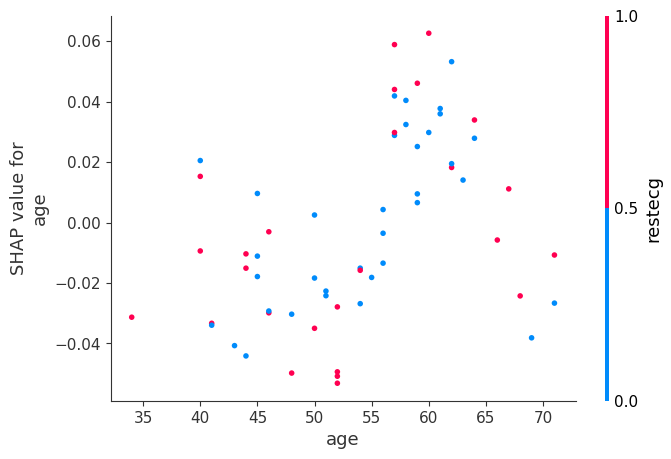

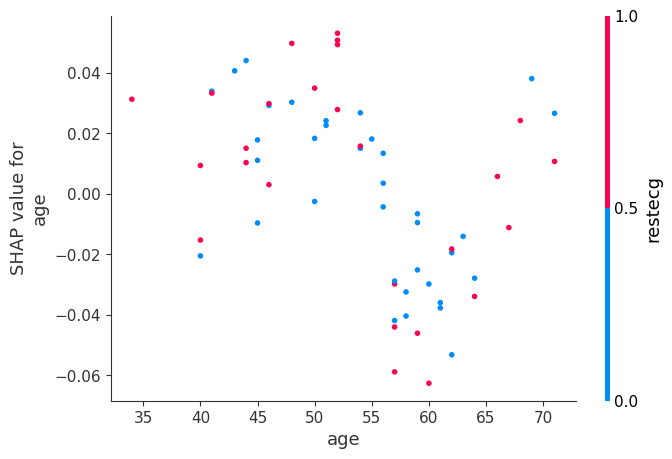

In [48]:
shap.dependence_plot("age", shap_values.values[:, :, 0], X_test)

shap.dependence_plot("age", shap_values.values[:, :, 1], X_test)

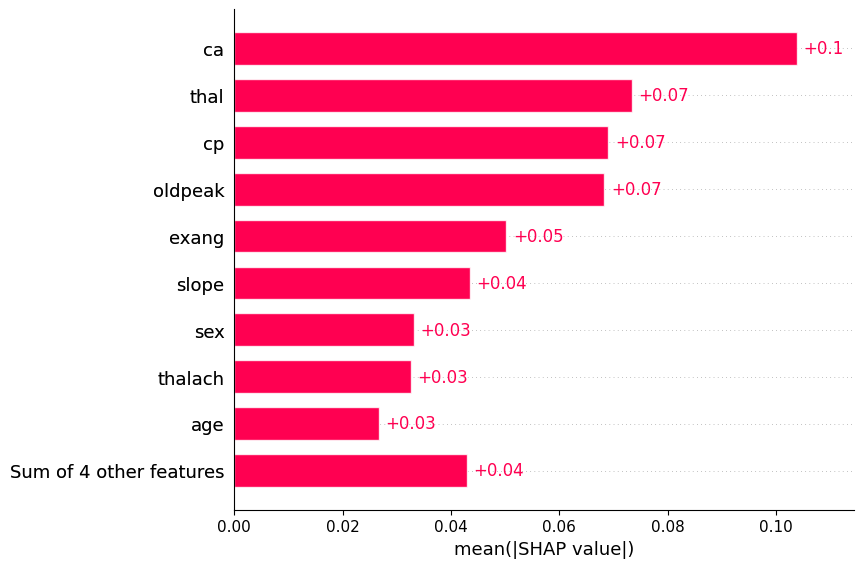

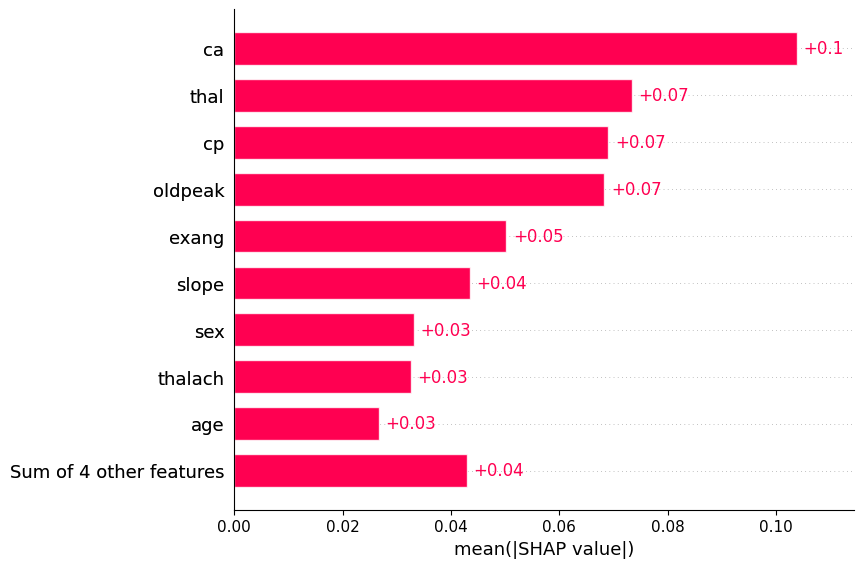

In [49]:
shap.plots.bar(shap_values[:, :, 0])  # for class 0
shap.plots.bar(shap_values[:, :, 1])  # for class 1


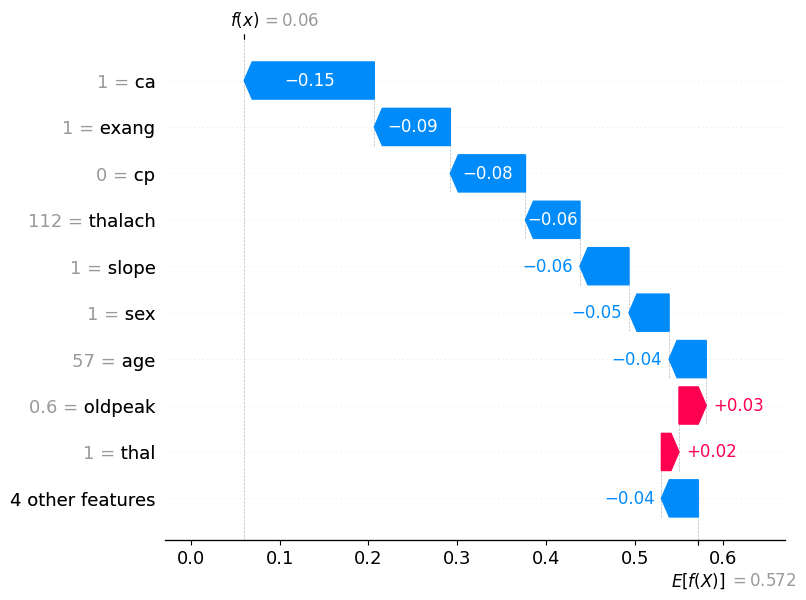

In [50]:
import shap

explainer = shap.Explainer(rf_model, X_train)

shap_values = explainer(X_test, check_additivity=False)

shap.plots.waterfall(shap_values[0, :, 1])

In [51]:
#shap.plots.bar(shap_values, max_display=13)
#shap.plots.bar(shap_values[:, :, 0], feature_names=["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach","exang", "oldpeak", "slope", "ca", "thal"])
shap.Explanation(values=shap_values[:, :, 0], 
                 feature_names=["age", "sex", "cp", "trestbps", "chol", 
                                "fbs", "restecg", "thalach", "exang", 
                                "oldpeak", "slope", "ca", "thal"])

.values =
array([[ 4.18697616e-02,  4.52038885e-02,  8.46309911e-02,
         6.35853182e-03,  1.55605157e-02,  1.65726193e-03,
         1.81197221e-02,  6.13996812e-02,  8.56921806e-02,
        -3.06871024e-02,  5.52328959e-02,  1.46610632e-01,
        -1.98489677e-02],
       [ 9.47297616e-03,  3.40090476e-02, -7.87677369e-02,
         4.54107132e-02,  2.42286902e-02,  2.06297618e-03,
         8.01476190e-03, -6.65833296e-03, -3.64103563e-02,
        -4.95017846e-02,  3.30757138e-02, -1.04416188e-01,
         7.12795225e-02],
       [ 5.88454752e-02,  3.19680953e-02, -7.65571413e-02,
        -4.75904774e-03, -1.36180955e-02, -4.01711905e-02,
        -2.14979758e-02, -2.17976186e-02, -1.93920232e-02,
        -5.05190463e-02, -4.43232135e-02,  1.36185950e-01,
         8.74358318e-02],
       [-3.54547616e-03, -3.26275790e-02,  1.02745514e-01,
        -6.67924602e-03, -2.45480157e-03, -1.04404749e-04,
         8.58861096e-03, -9.08511886e-03,  9.22520217e-02,
         2.85622611e-02,  5

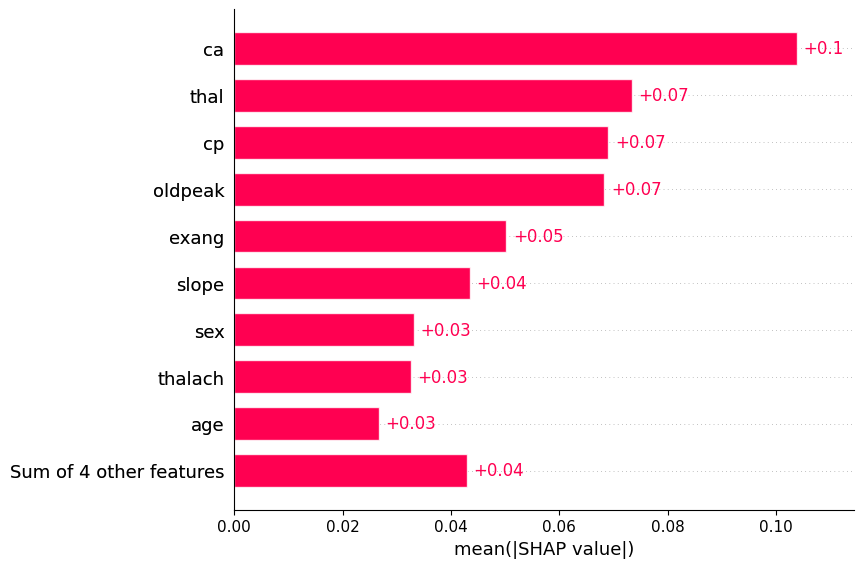

In [52]:
my_explanation=shap.Explanation(values=shap_values[:, :, 0], 
                 feature_names=["age", "sex", "cp", "trestbps", "chol", 
                                "fbs", "restecg", "thalach", "exang", 
                                "oldpeak", "slope", "ca", "thal"])
shap.plots.bar(my_explanation)

In [53]:
import shap
import pandas as pd

feature_names = ["age", "sex", "cp", "trestbps", "chol",
                 "fbs", "restecg", "thalach", "exang",
                 "oldpeak", "slope", "ca", "thal"]

X_test_df = pd.DataFrame(X_test, columns=feature_names)

my_explanation = shap.Explanation(
    values=shap_values[:, :, 0],
    data=X_test_df.values,
    feature_names=feature_names
)

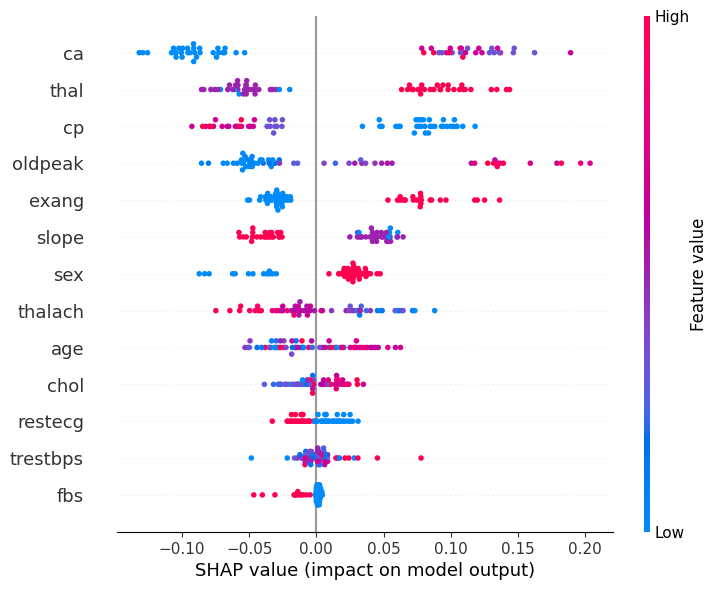

In [54]:
#1. Beeswarm Plot
shap.plots.beeswarm(my_explanation, max_display=13)

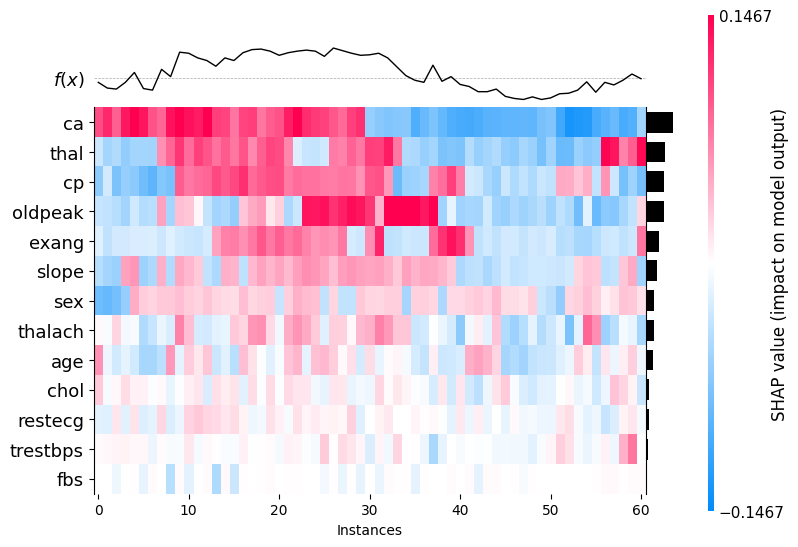

<Axes: xlabel='Instances'>

In [55]:
#2. Heatmap Plot
shap.plots.heatmap(my_explanation, max_display=13)

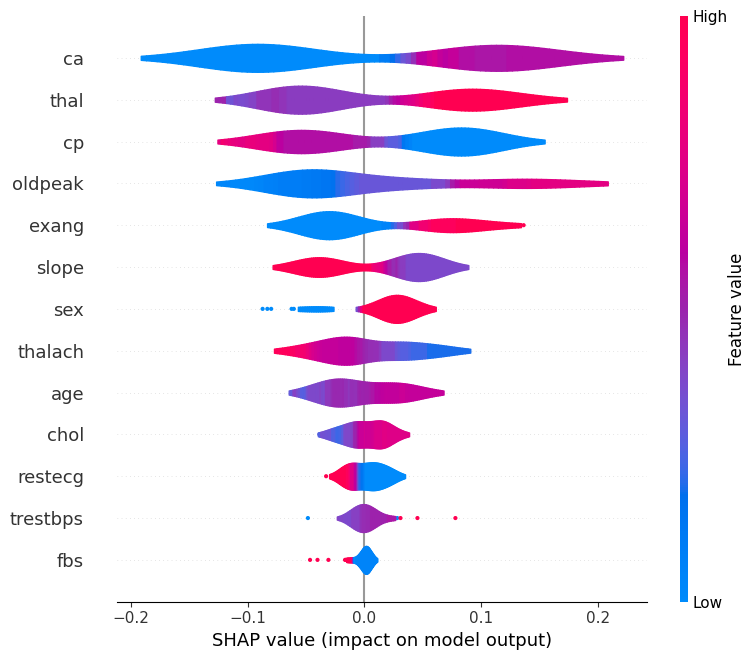

In [56]:
#3. Violin Plot
shap.summary_plot(shap_values[:, :, 0], X_test_df, plot_type="violin")

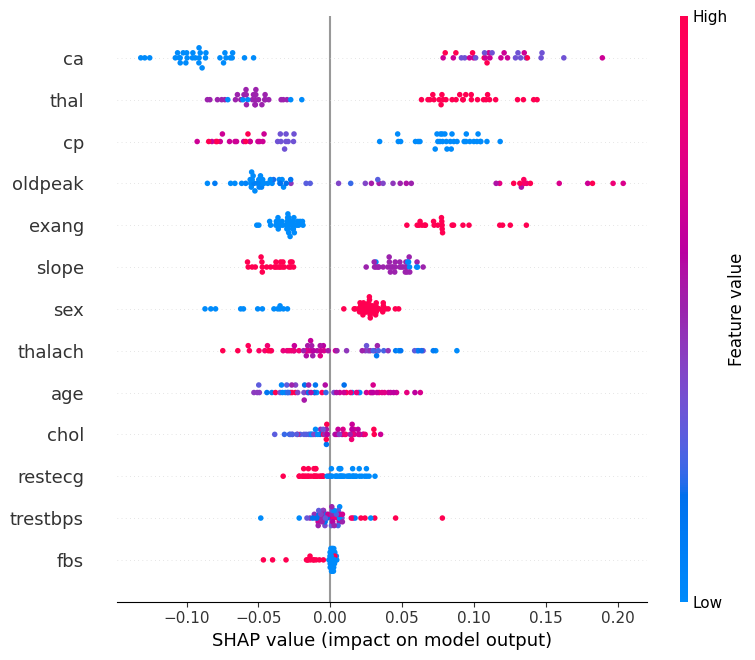

In [57]:
#4. Dot Summary Plot
shap.summary_plot(shap_values[:, :, 0], X_test_df, plot_type="dot")

In [58]:
print(np.array(shap_values).shape)

(61, 13, 2)


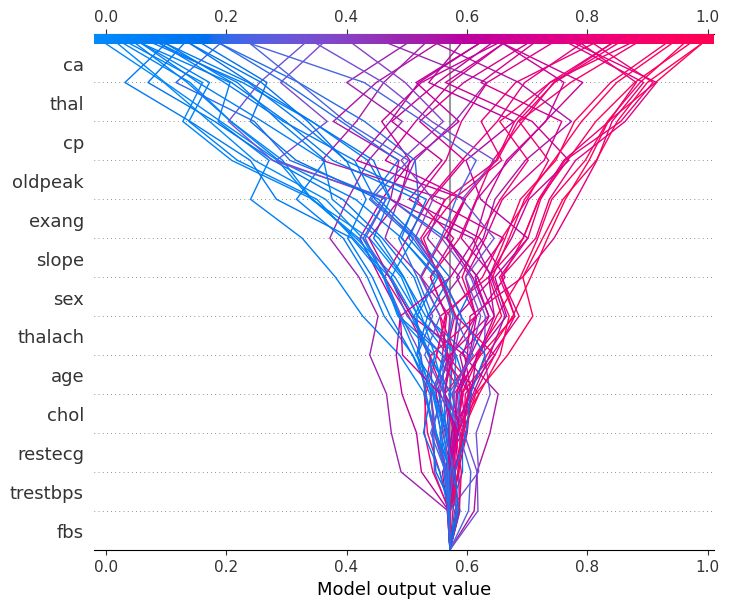

In [59]:
#5. Decision Plot
# shap.decision_plot(
#     explainer.expected_value[1],
#     shap_values[:, :, 1],
#     X_test_df,
#     feature_names=X_test_df.columns.tolist()
# )
shap.decision_plot(
    explainer.expected_value[1],
    shap_values.values[:, :, 1],   # use .values to extract NumPy array
    X_test_df,
    feature_names=X_test_df.columns.tolist()
)


In [60]:
# #6. Force Plot
# import shap
# shap_values_matrix = shap_values.values[:, :, 1]
# shap.initjs()

# shap.force_plot(
#     explainer.expected_value[1],
#     shap_values[0, :, 1],
#     X_test_df.iloc[0, :],
#     feature_names=X_test_df.columns.tolist()
# )
import shap

# 1. Initialize JS for the notebook
shap.initjs()

# 2. Extract the SHAP values for the first person (index 0) 
# and for the positive class (index 1)
# This keeps the metadata (feature names, base value) intact.
single_prediction_explanation = shap_values[0, :, 1]

# 3. Generate the Force Plot
# Using .plots.force is the modern replacement for shap.force_plot()
shap.plots.force(single_prediction_explanation)






In [61]:
#7. Scatter Plot with color by another feature

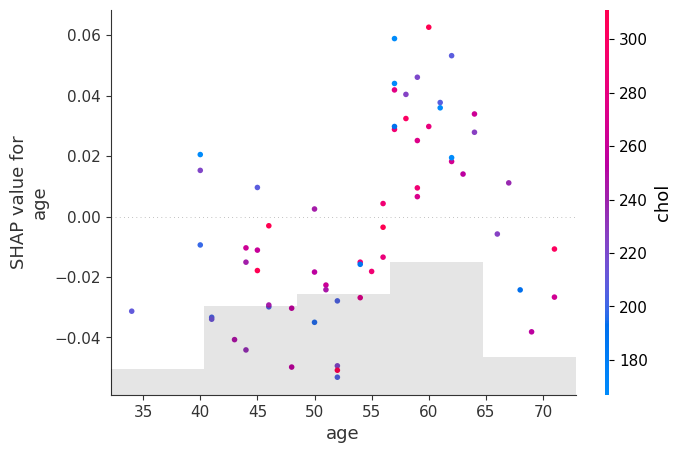

In [62]:
#a.age colored by chol
shap.plots.scatter(my_explanation[:, "age"], color=my_explanation[:, "chol"])

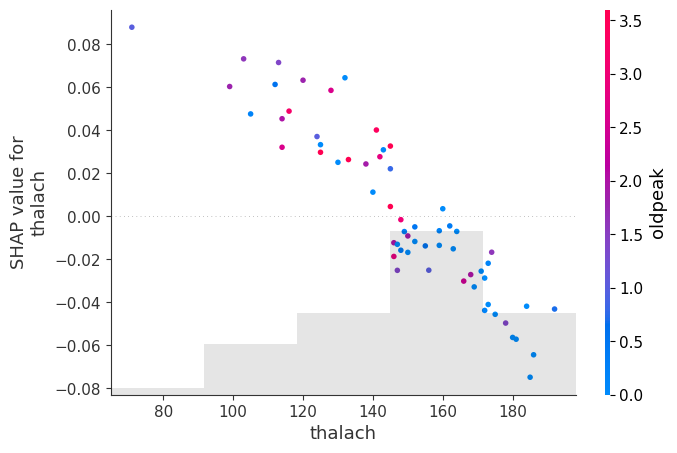

In [63]:
#b.thalach colored by oldpeak
shap.plots.scatter(my_explanation[:, "thalach"], color=my_explanation[:, "oldpeak"])

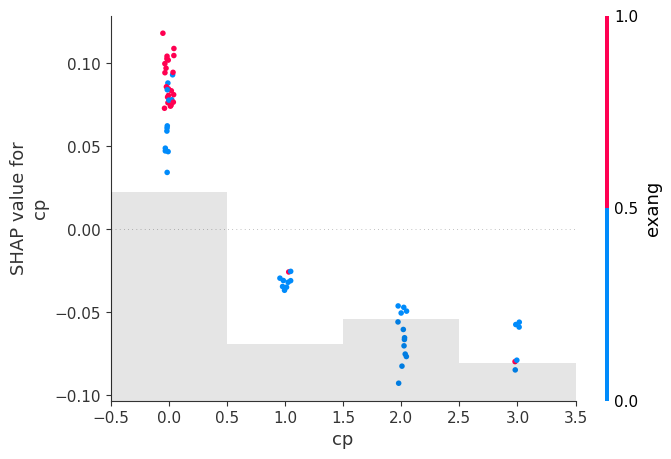

In [64]:
#c.cp colored by exang
shap.plots.scatter(my_explanation[:, "cp"], color=my_explanation[:, "exang"])

In [65]:
#8. Partial Dependence Style SHAP Scatter

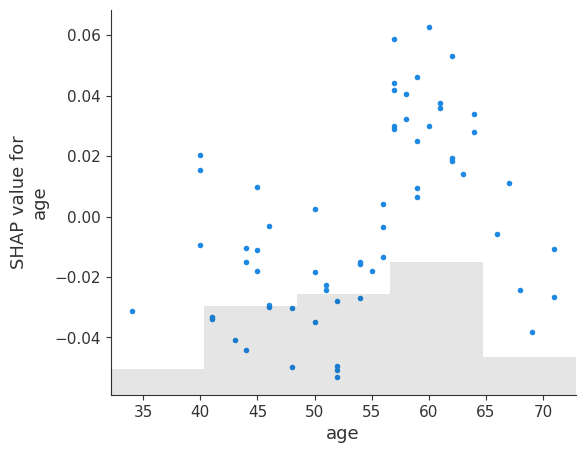

In [66]:
#a.age
shap.plots.scatter(my_explanation[:, "age"])

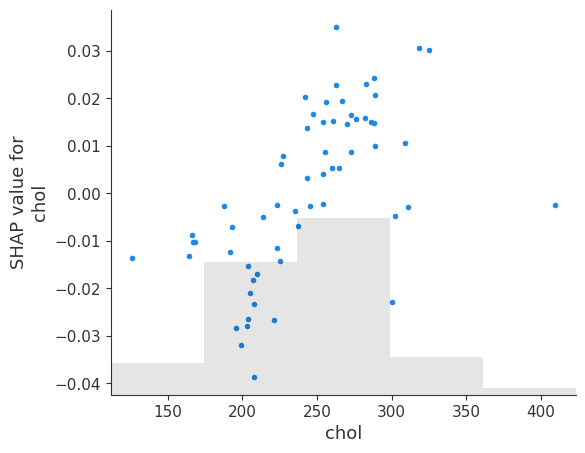

In [67]:
#B.chol
shap.plots.scatter(my_explanation[:, "chol"])

In [68]:
#9. Interaction-based Dependence Plot

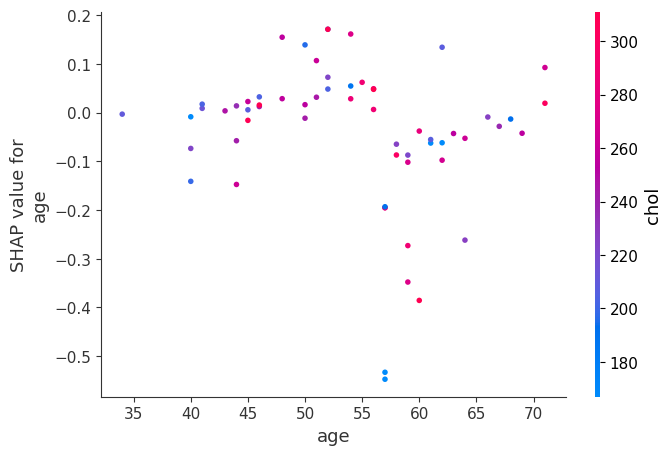

In [69]:
# # # #a.age with chol interaction
# # explainer = shap.TreeExplainer(model)
# # shap_values = explainer(X_test_df)

# # shap.dependence_plot(
# #     "age",
# #     shap_values[:, :, 1],
# #     X_test_df,
# #     interaction_index="chol"
# # )

import shap

# 1. Initialize the explainer and get values (already done)
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test_df)

# 2. Extract the raw SHAP values for the positive class (Class 1)
# Use .values to convert the Explanation object slice into a numpy array
# This avoids the "tuple index out of range" and matching column errors
shap_values_matrix = shap_values.values[:, :, 1]

# 3. Plot
shap.dependence_plot(
    "age",
    shap_values_matrix,
    X_test_df,
    interaction_index="chol"
)

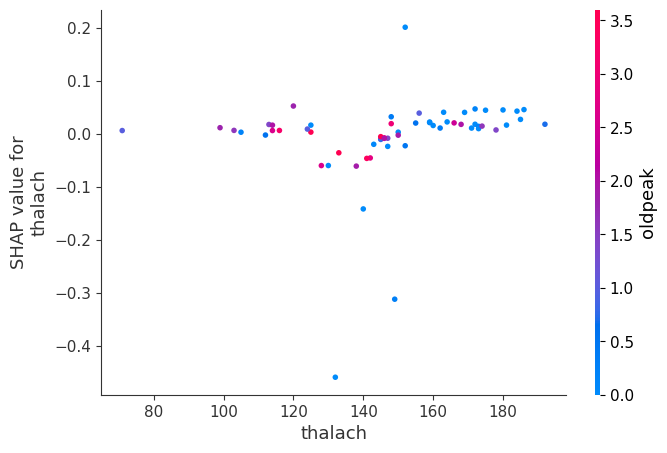

In [70]:
shap_values_matrix = shap_values.values[:, :, 1]

# Now pass the matrix and the DataFrame
shap.dependence_plot(
    "thalach",
    shap_values_matrix,
    X_test_df,
    interaction_index="oldpeak"
)

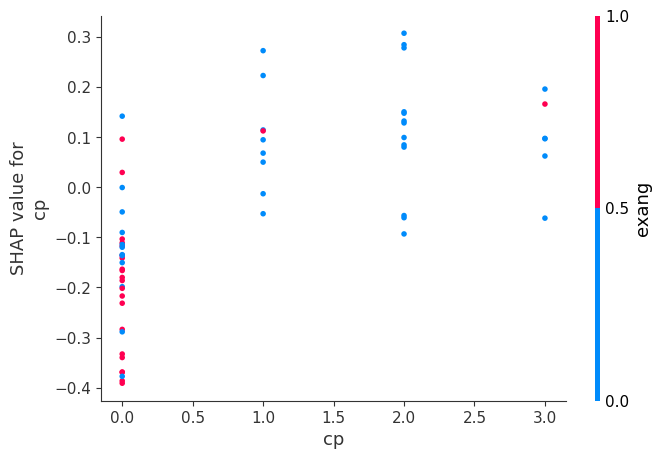

In [71]:
shap_values_matrix = shap_values.values[:, :, 1]
#c.cp with exang interaction
shap.dependence_plot(
    "cp",
    shap_values_matrix,
    X_test_df,
    interaction_index="exang"
)

In [72]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='str')

In [73]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [74]:
!pip install psycopg2-binary


[notice] A new release of pip is available: 26.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [75]:
import psycopg2

conn = psycopg2.connect(
    database="Heart_disease",
    user="postgres",
    password="YOUR_PASSWORD",
    host="localhost",
    port="5432"
)

cursor = conn.cursor()

print("Connected successfully ")

Connected successfully 


In [58]:
#conn.rollback()

In [76]:
cursor.execute("""
CREATE TABLE IF NOT EXISTS patient (
    id SERIAL PRIMARY KEY,
    age INT,
    sex INT,
    cp INT,
    trestbps INT,
    chol INT,
    fbs INT,
    restecg INT,
    thalach INT,
    exang INT,
    oldpeak FLOAT,
    slope INT,
    ca INT,
    thal INT,
    target INT,
    prediction INT,
    probability FLOAT
);
""")

conn.commit()

In [77]:
data = []

for _, row in df.iterrows():
    data.append((
        int(row['age']),
        int(row['sex']),
        int(row['cp']),
        int(row['trestbps']),
        int(row['chol']),
        int(row['fbs']),
        int(row['restecg']),
        int(row['thalach']),
        int(row['exang']),
        float(row['oldpeak']),
        int(row['slope']),
        int(row['ca']),
        int(row['thal']),
        int(row['target'])
    ))

cursor.executemany("""
INSERT INTO patient (
    age, sex, cp, trestbps, chol,
    fbs, restecg, thalach, exang,
    oldpeak, slope, ca, thal, target
) VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s, %s, %s, %s, %s, %s)
""", data)

conn.commit()

In [78]:
cursor.execute("SELECT * FROM patient")
rows = cursor.fetchall()

df = pd.DataFrame(rows, columns=[
    'id',
    'age', 'sex', 'cp', 'trestbps', 'chol',
    'fbs', 'restecg', 'thalach', 'exang',
    'oldpeak', 'slope', 'ca', 'thal', 'target',
    'prediction', 'probability'
])

In [79]:
X = df[[
    'age', 'sex', 'cp', 'trestbps', 'chol',
    'fbs', 'restecg', 'thalach', 'exang',
    'oldpeak', 'slope', 'ca', 'thal'
]]

predictions = rf_model.predict(X)
probabilities = rf_model.predict_proba(X)[:, 1]

df['prediction'] = predictions
df['probability'] = probabilities

In [80]:
for _, row in df.iterrows():
    cursor.execute("""
        UPDATE patient
        SET prediction = %s,
            probability = %s
        WHERE id = %s
    """, (
        int(row['prediction']),
        float(row['probability']),
        int(row['id'])
    ))

conn.commit()

In [81]:
import joblib

joblib.dump(rf_model, "heart_model.pkl")

['heart_model.pkl']

In [82]:
model=joblib.load("heart_model.pkl")